In [1]:
!pip install -q torch torchvision diffusers transformers accelerate safetensors opencv-python pillow requests matplotlib

In [2]:
import torch
import numpy as np
import cv2
import requests
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from io import BytesIO

from torchvision import models
from torchvision.models import ResNet18_Weights
from diffusers import AutoPipelineForImage2Image

C:\Users\admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [3]:
image_url_1 = "https://images.unsplash.com/photo-1521572163474-6864f9cf17ab?w=768"
image_url_2 = "https://images.unsplash.com/photo-1564859228273-274232fdb516?w=768"

response_1 = requests.get(image_url_1, timeout=30)
response_1.raise_for_status()

response_2 = requests.get(image_url_2, timeout=30)
response_2.raise_for_status()

image_1 = Image.open(BytesIO(response_1.content)).convert("RGB")
image_2 = Image.open(BytesIO(response_2.content)).convert("RGB")

print("Input images loaded successfully.")
print("Image 1:", image_1.size)
print("Image 2:", image_2.size)

Input images loaded successfully.
Image 1: (768, 768)
Image 2: (768, 1152)


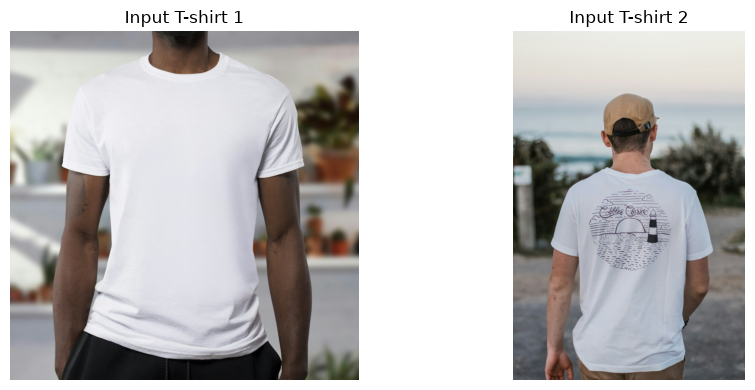

In [4]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_1)
plt.title("Input T-shirt 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_2)
plt.title("Input T-shirt 2")
plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
image_1 = ImageOps.fit(image_1, (512, 512))
image_2 = ImageOps.fit(image_2, (512, 512))

image_1_cv = cv2.cvtColor(np.array(image_1), cv2.COLOR_RGB2BGR)
image_2_cv = cv2.cvtColor(np.array(image_2), cv2.COLOR_RGB2BGR)

image_1_cv = cv2.fastNlMeansDenoisingColored(
    image_1_cv, None, 3, 3, 7, 21
)

image_2_cv = cv2.fastNlMeansDenoisingColored(
    image_2_cv, None, 3, 3, 7, 21
)

image_1 = Image.fromarray(
    cv2.cvtColor(image_1_cv, cv2.COLOR_BGR2RGB)
)

image_2 = Image.fromarray(
    cv2.cvtColor(image_2_cv, cv2.COLOR_BGR2RGB)
)

print("Preprocessing completed.")
print("Final dimensions:", image_1.size, image_2.size)

Preprocessing completed.
Final dimensions: (512, 512) (512, 512)


In [6]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

weights = ResNet18_Weights.DEFAULT

cnn = models.resnet18(weights=weights)
cnn.fc = torch.nn.Identity()
cnn = cnn.to(device)
cnn.eval()

cnn_transform = weights.transforms()

print("CNN loaded successfully.")
print("Device:", device)
print("Feature extractor: ResNet18")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\admin/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 59.3MB/s]


CNN loaded successfully.
Device: cpu
Feature extractor: ResNet18


In [7]:
input_tensor_1 = cnn_transform(image_1).unsqueeze(0).to(device)
input_tensor_2 = cnn_transform(image_2).unsqueeze(0).to(device)

with torch.no_grad():
    features_1 = cnn(input_tensor_1)
    features_2 = cnn(input_tensor_2)

features_1 = features_1.cpu().numpy().flatten()
features_2 = features_2.cpu().numpy().flatten()

print("Image 1 feature shape:", features_1.shape)
print("Image 2 feature shape:", features_2.shape)

Image 1 feature shape: (512,)
Image 2 feature shape: (512,)


In [8]:
histogram_1 = cv2.calcHist(
    [image_1_cv], [0, 1, 2], None,
    [4, 4, 4], [0, 256, 0, 256, 0, 256]
)

histogram_2 = cv2.calcHist(
    [image_2_cv], [0, 1, 2], None,
    [4, 4, 4], [0, 256, 0, 256, 0, 256]
)

histogram_1 = histogram_1.flatten().astype(np.float32)
histogram_2 = histogram_2.flatten().astype(np.float32)

histogram_1 = histogram_1 / (histogram_1.sum() + 1e-8)
histogram_2 = histogram_2 / (histogram_2.sum() + 1e-8)

print("Colour feature shape:", histogram_1.shape)

Colour feature shape: (64,)


In [9]:
colour_features = np.array([
    histogram_1,
    histogram_2
])

cnn_features = np.array([
    features_1,
    features_2
])

colour_bipolar = np.where(
    colour_features > 0, 1, -1
).astype(np.float32)

cnn_bipolar = np.where(
    cnn_features >= np.median(cnn_features, axis=1, keepdims=True),
    1, -1
).astype(np.float32)

print("BAM colour input:", colour_bipolar.shape)
print("BAM CNN input:", cnn_bipolar.shape)

BAM colour input: (2, 64)
BAM CNN input: (2, 512)


In [10]:
bam_weights = np.zeros((64, 512), dtype=np.float32)

bam_weights += np.outer(
    colour_bipolar[0], cnn_bipolar[0]
)

bam_weights += np.outer(
    colour_bipolar[1], cnn_bipolar[1]
)

print("BAM training completed.")
print("BAM weight matrix:", bam_weights.shape)

BAM training completed.
BAM weight matrix: (64, 512)


In [11]:
recalled_cnn = np.sign(
    colour_bipolar[0] @ bam_weights
)

recalled_cnn[recalled_cnn == 0] = 1

recalled_colour = np.sign(
    recalled_cnn @ bam_weights.T
)

recalled_colour[recalled_colour == 0] = 1

recalled_cnn = np.sign(
    recalled_colour @ bam_weights
)

recalled_cnn[recalled_cnn == 0] = 1

print("Forward recall shape:", recalled_cnn.shape)
print("Reverse recall shape:", recalled_colour.shape)

Forward recall shape: (512,)
Reverse recall shape: (64,)


In [12]:
mixed_colour = (histogram_1 + histogram_2) / 2

mixed_colour = mixed_colour / (
    mixed_colour.sum() + 1e-8
)

mixed_colour_bipolar = np.where(
    mixed_colour > 0, 1, -1
).astype(np.float32)

recalled_cnn = np.sign(
    mixed_colour_bipolar @ bam_weights
)

recalled_cnn[recalled_cnn == 0] = 1

recalled_colour = np.sign(
    recalled_cnn @ bam_weights.T
)

recalled_colour[recalled_colour == 0] = 1

recalled_cnn = np.sign(
    recalled_colour @ bam_weights
)

recalled_cnn[recalled_cnn == 0] = 1

similarity_1 = np.dot(
    recalled_cnn, cnn_bipolar[0]
) / len(recalled_cnn)

similarity_2 = np.dot(
    recalled_cnn, cnn_bipolar[1]
) / len(recalled_cnn)

selected_index = int(similarity_2 > similarity_1)

print("Similarity with image 1:", similarity_1)
print("Similarity with image 2:", similarity_2)
print("BAM-selected reference:", selected_index + 1)

Similarity with image 1: 0.4140625
Similarity with image 2: 1.0
BAM-selected reference: 2


In [13]:
generator_dtype = (
    torch.float16 if device.type != "cpu"
    else torch.float32
)

pipe = AutoPipelineForImage2Image.from_pretrained(
    "stabilityai/sd-turbo",
    torch_dtype=generator_dtype,
    use_safetensors=True
)

pipe = pipe.to(device)

print("Image-generation model loaded.")
print("Model: stabilityai/sd-turbo")
print("Device:", device)

C:\Users\admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\utils\_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
C:\Users\admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\admin\.cache\huggingface\hub\models--stabilityai--sd-turbo. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run

Image-generation model loaded.
Model: stabilityai/sd-turbo
Device: cpu


In [14]:
source_images = [
    image_1,
    image_2,
    image_1 if selected_index == 0 else image_2
]

prompts = [
    "Professional fashion product photograph of a red cotton crew neck T-shirt with a bold black geometric graphic print on the front, clean white studio background, realistic fabric texture, centered garment, no person, no text, no watermark",

    "Professional fashion product photograph of a black cotton crew neck T-shirt with a red modern geometric graphic print, clean white studio background, realistic fabric texture, centered garment, no person, no text, no watermark",

    (
        "Professional fashion product photograph of a "
        + (
            "red and black streetwear T-shirt with bold geometric graphics"
            if selected_index == 0
            else "black and red streetwear T-shirt with bold graphic accents"
        )
        + ", inspired by the selected reference design, clean white studio background, "
        "realistic cotton fabric, centered garment, no person, no text, no watermark"
    )
]

print("Three prompts prepared.")

Three prompts prepared.


In [15]:
generated_images = []

for i in range(3):
    print("Generating output", i + 1, "...")

    generated = pipe(
        prompt=prompts[i],
        image=source_images[i],
        strength=0.75,
        num_inference_steps=4,
        guidance_scale=0.0
    ).images[0]

    generated_images.append(generated)

print("All three outputs generated.")

Generating output 1 ...


100%|██████████| 3/3 [00:03<00:00,  1.14s/it]


Generating output 2 ...


100%|██████████| 3/3 [00:03<00:00,  1.06s/it]


Generating output 3 ...


100%|██████████| 3/3 [00:03<00:00,  1.08s/it]


All three outputs generated.


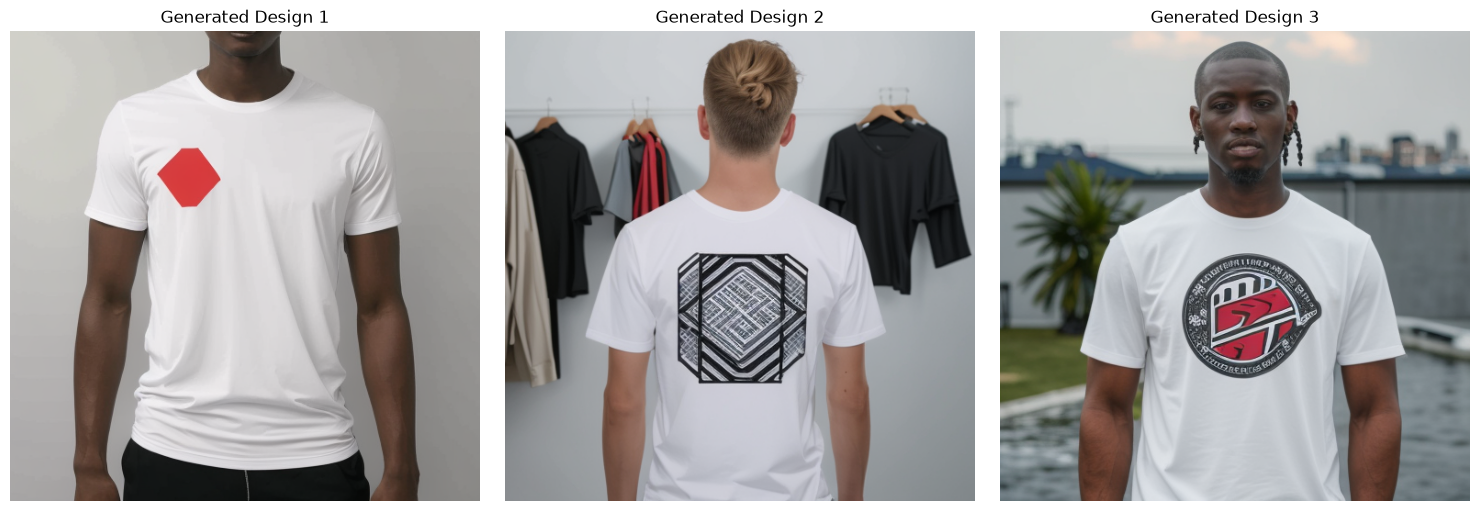

In [16]:
plt.figure(figsize=(15, 5))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(generated_images[i])
    plt.title("Generated Design " + str(i + 1))
    plt.axis("off")

plt.tight_layout()
plt.show()

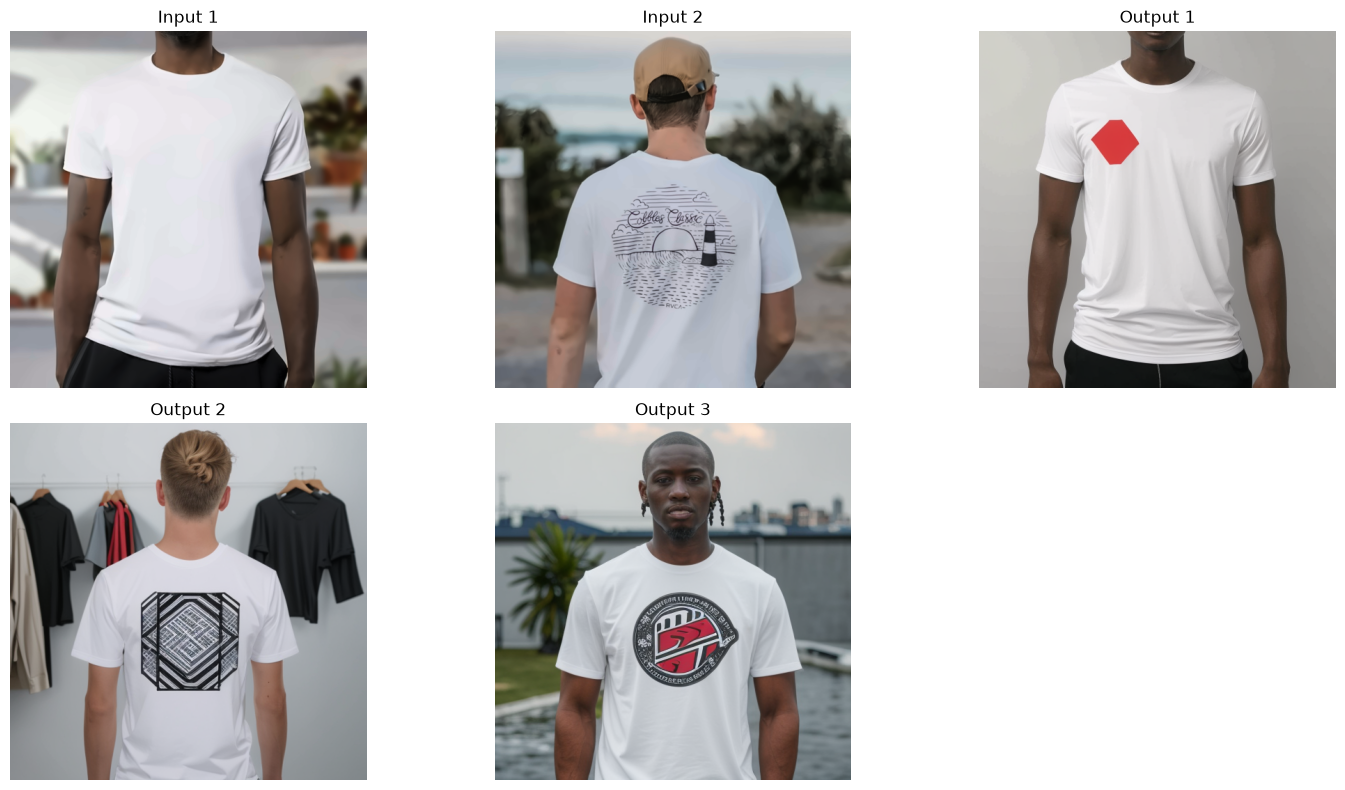

In [17]:
plt.figure(figsize=(15, 8))

all_images = [
    image_1,
    image_2,
    generated_images[0],
    generated_images[1],
    generated_images[2]
]

titles = [
    "Input 1",
    "Input 2",
    "Output 1",
    "Output 2",
    "Output 3"
]

for i in range(5):
    plt.subplot(2, 3, i + 1)
    plt.imshow(all_images[i])
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
generated_images[0].save("tshirt_output_1.png")
generated_images[1].save("tshirt_output_2.png")
generated_images[2].save("tshirt_output_3.png")

print("Saved:")
print("tshirt_output_1.png")
print("tshirt_output_2.png")
print("tshirt_output_3.png")

Saved:
tshirt_output_1.png
tshirt_output_2.png
tshirt_output_3.png
